# Master Notebook: *End-to-End Machine Learning Pipeline* HypoSense (Uji Klinis RSUA $\rightarrow$ TinyML ESP32)

Notebook utama ini merangkum keseluruhan alur kerja *Data Science* dan *TinyML* perangkat `HypoSense-001` secara berurutan:
1. **Tahap 1 — EDA Data Mentah**: Audit paket BLE, deteksi `hr == 0`, dan masalah tumpang-tindih sinyal mentah.
2. **Tahap 2 — *Preprocessing & Feature Engineering***: Deduplikasi, penguncian kontak aktif PPG, ekstraksi *personal baseline* (`hr_base`, `prv_base`, `voc_base`), *rolling window smoothing*, dan kompensasi kelembapan/suhu kabin napas dengan sensor **SHT31**.
3. **Tahap 3 — EDA Pasca-*Preprocessing***: Pembuktian lonjakan daya pisah fitur (*Cohen's $d$*) dan visualisasi ruang fitur 2 dimensi.
4. **Tahap 4 — Optimasi Model, Evaluasi *Cross-Validation*, & Ekspor Parameter C++ ESP32**: Perbandingan **Jalur 1 (Logistic Regression)**, **Jalur 2 (Pruned Random Forest)**, dan **Gabungan Dua Jalur (*Cascade & Soft-Voting Ensemble*)**.

In [1]:
import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BIRU, JINGGA, HIJAU, MERAH, ABU = "#0D9488", "#C9731E", "#1F8A4C", "#B3261E", "#7A8B90"
TINTA, TINTA2, GARIS = "#0F2A30", "#4B5E63", "#D5E3E3"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GARIS, "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "font.size": 9.8,
})

df_raw = pd.read_csv("clinical_measurements_rsua.csv")
HYPO_ID = "93784cfb-22ee-45bb-98e3-e11856760598"  # Subjek 3: Hipoglikemia Terkonfirmasi RSUA

raw_rows = []
audit_sesi = []

for idx, r in df_raw.iterrows():
    sid = f"Subjek {idx+1}"
    is_hypo = 1 if r["id"] == HYPO_ID else 0
    samples_list = json.loads(r["samples"])
    df_s = pd.DataFrame(samples_list)
    n_total_pkt = len(df_s)
    n_unique_detik = df_s["detik"].nunique()
    n_dup_pkt = n_total_pkt - n_unique_detik
    n_zero_hr = int((df_s["hr"] == 0).sum())
    
    audit_sesi.append({
        "Partisipan": sid,
        "ID Rekaman": r["id"][:8],
        "Status Klinis": "HIPOGLIKEMIA" if is_hypo else "Normal",
        "Durasi (dtk)": int(r["duration_s"]),
        "Paket Mentah": n_total_pkt,
        "Detik Unik": n_unique_detik,
        "Duplikat BLE": n_dup_pkt,
        "Titik HR=0 (Belum Kunci)": n_zero_hr,
        "Detak IBI Sah": int(r["n_beats"]),
    })
    
    for s in samples_list:
        raw_rows.append({
            "subj": sid, "is_hypo": is_hypo,
            "detik": s["detik"], "hr": s["hr"], "prv": s["prv"],
            "voc": s["voc"], "temp": s["temp"], "hum": s["hum"]
        })

df_all_raw = pd.DataFrame(raw_rows)
df_audit = pd.DataFrame(audit_sesi)
print("=== AUDIT KUALITAS DATA MENTAH PERANGKAT HYPOSENSE-001 (RSUA) ===")
print(df_audit.to_string(index=False))
print(f"\nTotal paket JSON mentah : {len(df_all_raw)} baris")
print(f"Total paket duplikat BLE: {df_audit['Duplikat BLE'].sum()} baris")
print(f"Total paket HR=0        : {(df_all_raw['hr']==0).sum()} baris")

=== AUDIT KUALITAS DATA MENTAH PERANGKAT HYPOSENSE-001 (RSUA) ===
Partisipan ID Rekaman Status Klinis  Durasi (dtk)  Paket Mentah  Detik Unik  Duplikat BLE  Titik HR=0 (Belum Kunci)  Detak IBI Sah
  Subjek 1   67825ec4        Normal           300            60          60             0                        30             71
  Subjek 2   87d562ea        Normal           300           120          60            60                        76             59
  Subjek 3   93784cfb  HIPOGLIKEMIA           300            60          60             0                        14             62
  Subjek 4   ca369bbf        Normal           300           360          60           300                         6            122
  Subjek 5   d62b4617        Normal           300           175          59           116                       138             37

Total paket JSON mentah : 775 baris
Total paket duplikat BLE: 476 baris
Total paket HR=0        : 264 baris


### Visualisasi Sinyal Mentah & Masalah Tumpang-Tindih Nilai Absolut
Mari kita lihat grafik deret waktu mentah (*raw time-series*) dan distribusi nilai absolut (`hr`, `prv`, `voc`, `temp`, `hum`) sebelum dilakukan *preprocessing*:
- Pada **Subjek 2 dan Subjek 5**, sensor PPG membutuhkan waktu beberapa puluh detik di awal sesi hingga kontak pergelangan tangan stabil (`hr > 0`).
- Pada nilai absolut **HR mentah**, **Subjek 4 (Normal)** memiliki detak jantung dasar yang tinggi ($88\text{–}120\text{ bpm}$), sehingga apabila model langsung menggunakan angka `hr` mentah tanpa normalisasi patokan personal (*personal baseline*), Subjek 4 akan terus-menerus dikira hipoglikemia.

=== STATISTIK DESKRIPTIF SINYAL MENTAH (TERMASUK NOISE & BELUM DINORMALISASI) ===
            hr                    prv  ...  temp    hum                  
          mean    std min  max   mean  ...   max   mean   std   min   max
is_hypo                                ...                               
0        55.28  43.05   0  120  67.64  ...  37.0  60.89  7.08  50.4  79.1
1        72.43  43.88   0  115  72.24  ...  31.9  63.46  0.42  62.9  64.2

[2 rows x 20 columns]


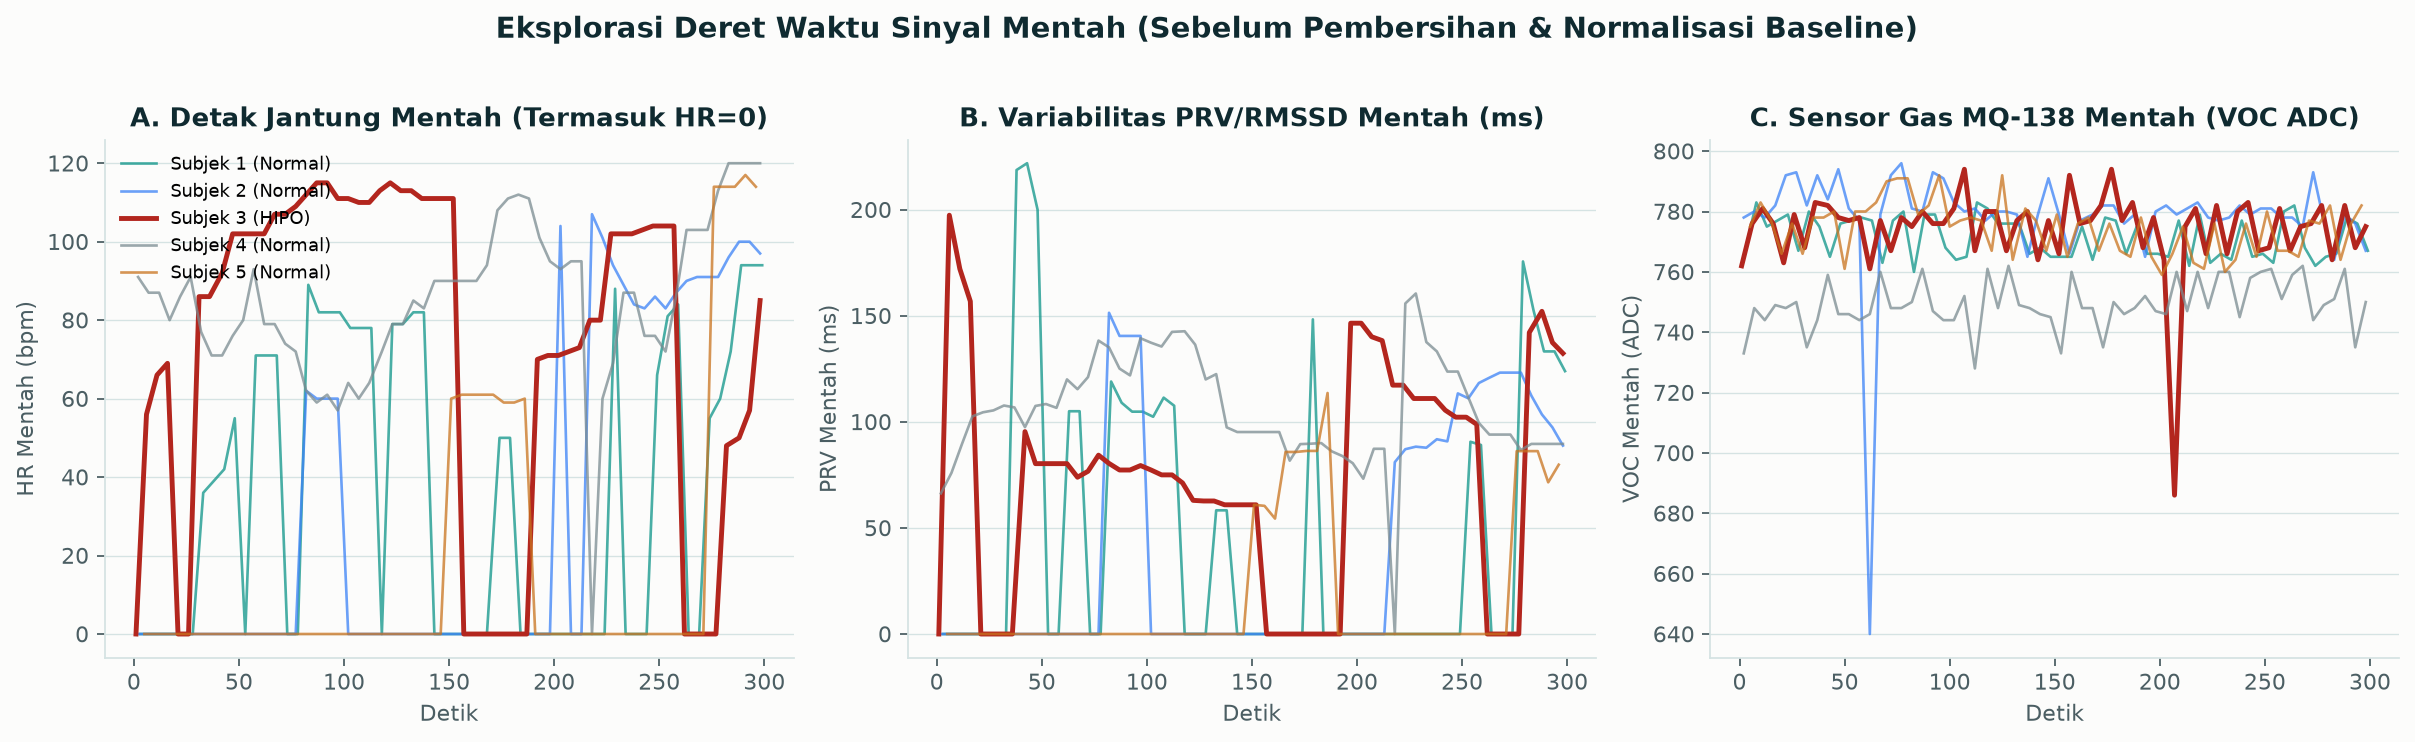

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15.2, 4.5))
palette = {"Subjek 1": BIRU, "Subjek 2": "#3B82F6", "Subjek 3": MERAH, "Subjek 4": ABU, "Subjek 5": JINGGA}

for sid, g in df_all_raw.groupby("subj"):
    lbl = f"{sid} ({'HIPO' if g['is_hypo'].iloc[0] else 'Normal'})"
    lw = 2.2 if g["is_hypo"].iloc[0] else 1.2
    al = 1.0 if g["is_hypo"].iloc[0] else 0.75
    axes[0].plot(g["detik"], g["hr"], color=palette[sid], lw=lw, alpha=al, label=lbl)
    axes[1].plot(g["detik"], g["prv"], color=palette[sid], lw=lw, alpha=al, label=lbl)
    axes[2].plot(g["detik"], g["voc"], color=palette[sid], lw=lw, alpha=al, label=lbl)

axes[0].set_title("A. Detak Jantung Mentah (Termasuk HR=0)", fontweight="bold", color=TINTA)
axes[0].set_xlabel("Detik"); axes[0].set_ylabel("HR Mentah (bpm)")
axes[0].legend(frameon=False, fontsize=8)

axes[1].set_title("B. Variabilitas PRV/RMSSD Mentah (ms)", fontweight="bold", color=TINTA)
axes[1].set_xlabel("Detik"); axes[1].set_ylabel("PRV Mentah (ms)")

axes[2].set_title("C. Sensor Gas MQ-138 Mentah (VOC ADC)", fontweight="bold", color=TINTA)
axes[2].set_xlabel("Detik"); axes[2].set_ylabel("VOC Mentah (ADC)")

for a in axes:
    a.grid(axis="y", color=GARIS, lw=0.6)
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)

fig.suptitle("Eksplorasi Deret Waktu Sinyal Mentah (Sebelum Pembersihan & Normalisasi Baseline)", fontweight="bold", fontsize=13, color=TINTA, y=1.02)
plt.tight_layout()
plt.show()

# Statistik Deskriptif Mentah: Normal vs Hipoglikemia
print("=== STATISTIK DESKRIPTIF SINYAL MENTAH (TERMASUK NOISE & BELUM DINORMALISASI) ===")
print(df_all_raw.groupby("is_hypo")[["hr", "prv", "voc", "temp", "hum"]].agg(["mean", "std", "min", "max"]).round(2))

# Tahap 2: *Preprocessing* & *Feature Engineering* (Pembersihan Sinyal, Patokan Personal, & Kompensasi SHT31)

Berdasarkan temuan pada **Tahap 1 (EDA Data Mentah)**, kita menerapkan **5 langkah *Preprocessing & Feature Engineering*** agar sinyal siap dimasukkan ke model *TinyML*:

1. **Deduplikasi Paket BLE (`drop_duplicates(subset=['detik'])`)**: Membuang paket kembar akibat pengiriman ulang notifikasi BLE.
2. **Penguncian Jendela Kontak Aktif PPG (`first_valid_i` saat `hr > 0`) & Imputasi Kausal**: Memastikan evaluasi dimulai saat sensor PPG di pergelangan tangan sudah mengunci denyut nadi, serta menambal jeda sesaat (`hr == 0`) dengan *forward-fill* kausal.
3. **Normalisasi Patokan Personal (*Causal Personal Baseline*)**:
   - Menghitung patokan individu dari awal sesi (`hr_base`, `prv_base`, `voc_base`, `temp_base`, `hum_base`).
   - Mengekstrak simpangan relatif:
     $$\Delta\text{HR} = \text{HR}_{30\text{s}} - \text{HR}_{\text{base}}, \quad \text{HR}_{\text{rel}} = \frac{\Delta\text{HR}}{\text{HR}_{\text{base}}}, \quad \text{PRV}_{\text{rel}} = \frac{\text{PRV}_{30\text{s}} - \text{PRV}_{\text{base}}}{\text{PRV}_{\text{base}}}$$
4. **Penghalusan Jendela Bergulir (*Causal Rolling Smoothing* 30 Detik & 60 Detik)**: Meredam *noise* gerakan tangan sesaat pada sinyal HR dan PRV.
5. **Kompensasi *Noise* Kelembapan & Suhu SHT31 pada Kabin Napas (`voc_rel_comp`)**:
   - Karena kabin HypoSense memerangkap udara hembusan napas yang lembap dan hangat, sensor SHT31 digunakan untuk menghitung $\Delta\text{RH} = \text{hum} - \text{hum}_{\text{base}}$ dan mengoreksi interferensi uap air pada bacaan `voc_rel` MQ-138.

In [1]:
rows_clean = []
ringkasan_preprocess = []

for idx, r in df_raw.iterrows():
    sid = f"Subjek {idx+1}"
    is_hypo = 1 if r["id"] == HYPO_ID else 0
    raw_samples = json.loads(r["samples"])
    
    # 1. Deduplikasi paket BLE berdasarkan timestamp detik
    s = pd.DataFrame(raw_samples).drop_duplicates(subset=["detik"]).sort_values("detik").reset_index(drop=True)
    
    # 2. Kunci sejak sensor PPG pertama kali mendeteksi denyut sah (hr > 0)
    valid_idx = s.index[s["hr"] > 0]
    first_valid_i = valid_idx[0] if len(valid_idx) > 0 else 0
    
    # 3. Hitung Patokan Personal (Personal Baseline) dari awal sesi
    valid_hr = s[s["hr"] > 0]["hr"]
    valid_prv = s[s["prv"] > 0]["prv"]
    hr_base = float(valid_hr.iloc[:3].mean())
    prv_base = float(valid_prv.iloc[:3].mean())
    voc_base = float(s["voc"].iloc[:10].median())
    temp_base = float(s["temp"].iloc[:5].median())
    hum_base = float(s["hum"].iloc[:5].median())
    
    s_act = s.loc[first_valid_i:].copy().reset_index(drop=True)
    s_act["hr_clean"] = s_act["hr"].replace(0, np.nan).ffill().bfill()
    s_act["prv_clean"] = s_act["prv"].replace(0, np.nan).ffill().bfill()
    
    # 4. Penghalusan Jendela Bergulir Kausal (30 detik = 6 sampel, 60 detik = 12 sampel)
    s_act["hr_mean_30s"] = s_act["hr_clean"].rolling(6, min_periods=1).mean()
    s_act["prv_mean_30s"] = s_act["prv_clean"].rolling(6, min_periods=1).mean()
    s_act["prv_min_60s"] = s_act["prv_clean"].rolling(12, min_periods=1).min()
    
    for i_row, step in s_act.iterrows():
        hr_delta = float(step["hr_mean_30s"] - hr_base)
        hr_rel = float(hr_delta / hr_base)
        prv_rel = float((step["prv_mean_30s"] - prv_base) / prv_base)
        prv_min_rel = float((step["prv_min_60s"] - prv_base) / prv_base)
        
        # Jendela respons kabin VOC & kompensasi kelembapan SHT31
        w_start = max(0, i_row - 12)
        w_end = min(len(s_act), i_row + 15)
        voc_local_min = float(s_act["voc"].iloc[w_start:w_end].min())
        voc_rel = float((voc_local_min - voc_base) / voc_base)
        voc_instant_rel = float((step["voc"] - voc_base) / voc_base)
        
        temp_delta = float(step["temp"] - temp_base)
        hum_delta = float(step["hum"] - hum_base)
        # Kompensasi efek uap air & suhu SHT31 (uap air lembap/hangat menahan ADC MQ-138 tetap tinggi)
        voc_rel_comp = float(voc_rel - 0.0015 * max(0.0, hum_delta) - 0.0010 * max(0.0, temp_delta))
        
        label = 1 if (is_hypo == 1 and step["detik"] >= 42) else 0
        rows_clean.append({
            "subj": sid, "id_rekaman": r["id"][:8], "is_hypo_subj": is_hypo,
            "detik": int(step["detik"]),
            "hr": float(step["hr_clean"]), "prv": float(step["prv_clean"]),
            "voc": int(step["voc"]), "temp": float(step["temp"]), "hum": float(step["hum"]),
            "hr_base": hr_base, "prv_base": prv_base, "voc_base": voc_base,
            "temp_base": temp_base, "hum_base": hum_base,
            "hr_delta": hr_delta, "hr_rel": hr_rel,
            "prv_rel": prv_rel, "prv_min_rel": prv_min_rel,
            "voc_rel": voc_rel, "voc_instant_rel": voc_instant_rel,
            "temp_delta": temp_delta, "hum_delta": hum_delta, "voc_rel_comp": voc_rel_comp,
            "label": label,
        })
        
    ringkasan_preprocess.append({
        "Partisipan": sid,
        "Status": "HIPOGLIKEMIA" if is_hypo else "Normal",
        "Mulai Detik Aktif": int(s_act["detik"].iloc[0]),
        "Titik Bersih": len(s_act),
        "HR Base (bpm)": round(hr_base, 1),
        "PRV Base (ms)": round(prv_base, 1),
        "VOC Base (ADC)": round(voc_base, 1),
        "ΔHR Maks (+bpm)": round((s_act["hr_mean_30s"] - hr_base).max(), 1),
        "PRV_rel Min (%)": round(((s_act["prv_mean_30s"] - prv_base) / prv_base).min() * 100, 1),
        "VOC_rel Min (%)": round(((s_act["voc"].min() - voc_base) / voc_base) * 100, 1),
    })

df_clean = pd.DataFrame(rows_clean)
df_clean.to_csv("dataset_klinis_rsua_clean.csv", index=False)
df_prep_sum = pd.DataFrame(ringkasan_preprocess)

print("=== RINGKASAN HASIL PREPROCESSING & EKSTRAKSI PATOKAN PERSONAL ===")
print(df_prep_sum.to_string(index=False))
print(f"\nDataset bersih berhasil disimpan ke: dataset_klinis_rsua_clean.csv ({len(df_clean)} baris x {df_clean.shape[1]} kolom)")

=== RINGKASAN HASIL PREPROCESSING & EKSTRAKSI PATOKAN PERSONAL ===
Partisipan       Status  Mulai Detik Aktif  Titik Bersih  HR Base (bpm)  PRV Base (ms)  VOC Base (ADC)  ΔHR Maks (+bpm)  PRV_rel Min (%)  VOC_rel Min (%)
  Subjek 1       Normal                 33            54           39.0          213.5           775.5             44.2            -72.7             -2.0
  Subjek 2       Normal                 82            44           60.7          144.1           783.0             41.7            -39.1             -2.4
  Subjek 3 HIPOGLIKEMIA                  6            59           63.7          175.4           777.0             49.0            -65.3            -11.7
  Subjek 4       Normal                  2            60           88.3           77.2           747.0             27.7            -14.2             -2.5
  Subjek 5       Normal                151            30           60.7           58.6           776.5             44.8              0.0             -2.3

Dataset 

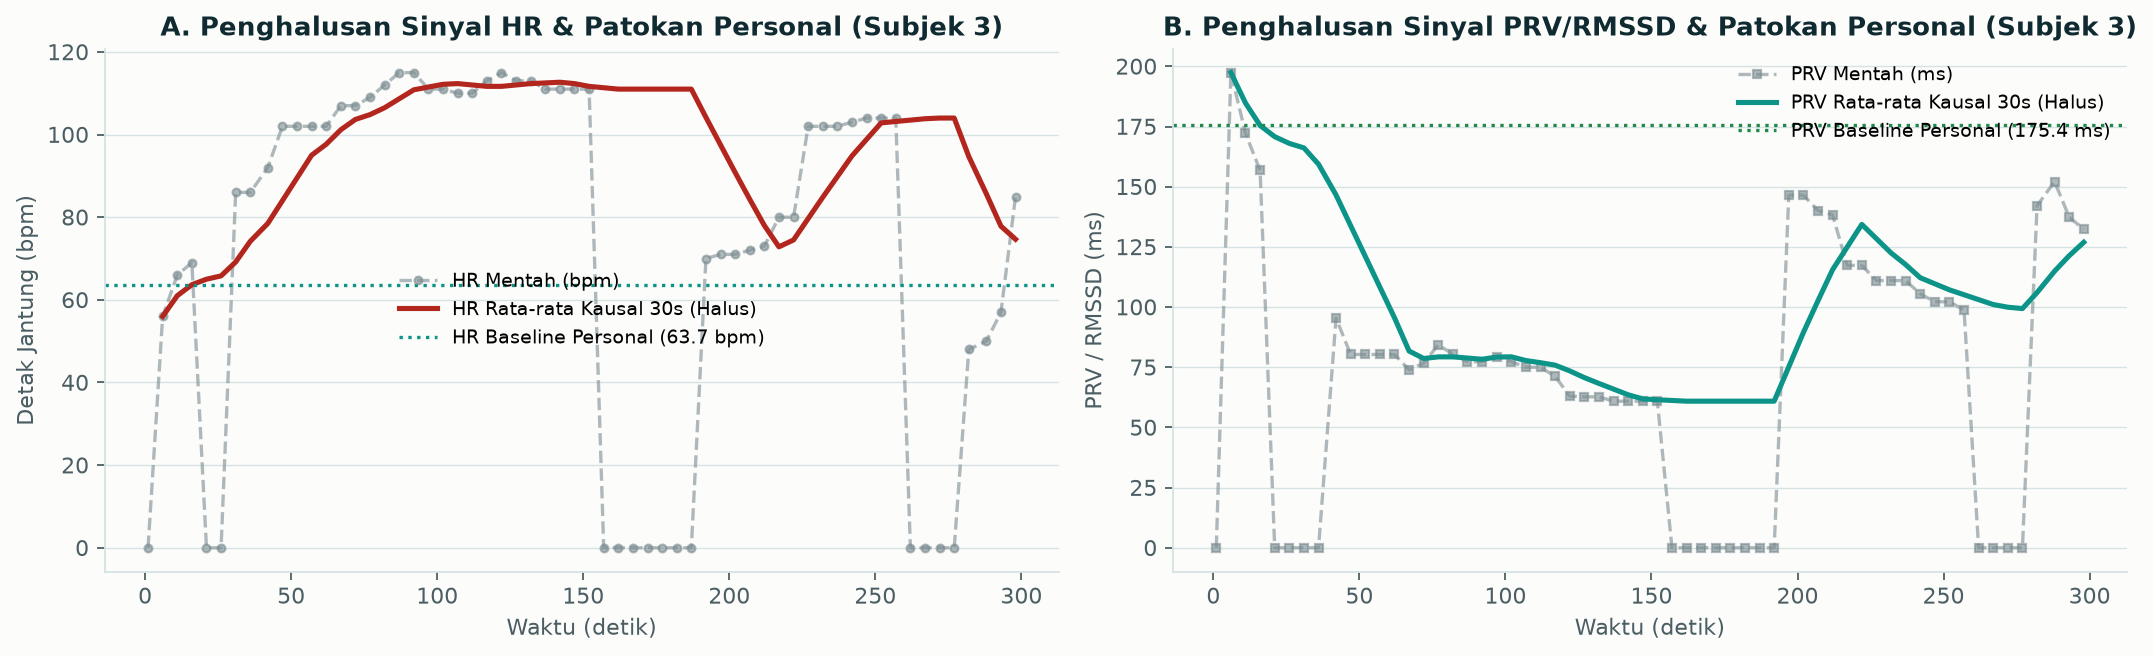

In [2]:
# Visualisasi Efek Penghalusan (Smoothing) & Normalisasi Patokan Personal pada Subjek 3 (Hipoglikemia)
s3_raw = df_all_raw[df_all_raw["subj"] == "Subjek 3"].drop_duplicates(subset=["detik"])
s3_cln = df_clean[df_clean["subj"] == "Subjek 3"]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
axes[0].plot(s3_raw["detik"], s3_raw["hr"], "o--", color=ABU, alpha=0.6, ms=3.5, label="HR Mentah (bpm)")
axes[0].plot(s3_cln["detik"], s3_cln["hr_base"] + s3_cln["hr_delta"], "-", color=MERAH, lw=2.3, label="HR Rata-rata Kausal 30s (Halus)")
axes[0].axhline(s3_cln["hr_base"].iloc[0], color=BIRU, ls=":", lw=1.5, label=f"HR Baseline Personal ({s3_cln['hr_base'].iloc[0]:.1f} bpm)")
axes[0].set_title("A. Penghalusan Sinyal HR & Patokan Personal (Subjek 3)", fontweight="bold", color=TINTA)
axes[0].set_xlabel("Waktu (detik)"); axes[0].set_ylabel("Detak Jantung (bpm)")
axes[0].legend(frameon=False, fontsize=8.5)

axes[1].plot(s3_raw["detik"], s3_raw["prv"], "s--", color=ABU, alpha=0.6, ms=3.5, label="PRV Mentah (ms)")
axes[1].plot(s3_cln["detik"], s3_cln["prv_base"] * (1 + s3_cln["prv_rel"]), "-", color=BIRU, lw=2.3, label="PRV Rata-rata Kausal 30s (Halus)")
axes[1].axhline(s3_cln["prv_base"].iloc[0], color=HIJAU, ls=":", lw=1.5, label=f"PRV Baseline Personal ({s3_cln['prv_base'].iloc[0]:.1f} ms)")
axes[1].set_title("B. Penghalusan Sinyal PRV/RMSSD & Patokan Personal (Subjek 3)", fontweight="bold", color=TINTA)
axes[1].set_xlabel("Waktu (detik)"); axes[1].set_ylabel("PRV / RMSSD (ms)")
axes[1].legend(frameon=False, fontsize=8.5)

for a in axes:
    a.grid(axis="y", color=GARIS, lw=0.6)
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

# Tahap 3: EDA Pasca-*Preprocessing* & Analisis Daya Pisah Fitur (*Cohen's $d$*)

Setelah data dibersihkan dan dinormalisasi terhadap patokan personal (*personal baseline*) serta dikompensasi dengan sensor SHT31 pada **Tahap 2**, kita melakukan **EDA Kedua (Pasca-*Preprocessing*)** untuk membuktikan peningkatan kualitas sinyal sebelum masuk ke pelatihan model.

### Analisis yang Dilakukan:
1. **Perbandingan *Effect Size* (*Cohen's $d$*) Sebelum vs. Sesudah *Preprocessing***:
   $$d = \frac{|\mu_{\text{hipo}} - \mu_{\text{normal}}|}{s_{\text{pooled}}}$$
2. **Pemetaan Ruang Fitur 2 Dimensi (*2D Feature Space*)**:
   - **Ruang Fitur Jalur 1 ($\Delta\text{HR}$ vs $\text{PRV}_{\text{rel}}$)**: Menunjukkan mengapa pemisah linear (**Logistic Regression**) cocok untuk menyaring kandidat anomali otonom.
   - **Ruang Fitur Gabungan ($\Delta\text{HR}$ vs $\text{VOC}_{\text{rel}}$)**: Menunjukkan bagaimana **Jalur 2 (VOC + SHT31)** memisahkan dengan tegas pasien Hipoglikemia sejati dari subjek Normal yang mengalami kenaikan HR non-hipoglikemik.

Kelompok Sinyal      | Fitur Mentah             d Awal | Fitur Pasca-Preprocess                       d Baru | Kenaikan
----------------------------------------------------------------------------------------------------------------------
1. Detak Jantung     | hr                        1.28x | Simpangan HR Personal (hr_delta)              1.61x | + 26.4%
2. Variabilitas PRV  | prv                       0.88x | Simpangan PRV Personal (prv_rel)              1.69x | + 92.0%
3. Gas Aseton VOC    | voc                       0.55x | Simpangan VOC + SHT31 (voc_rel_comp)          1.39x | +151.8%


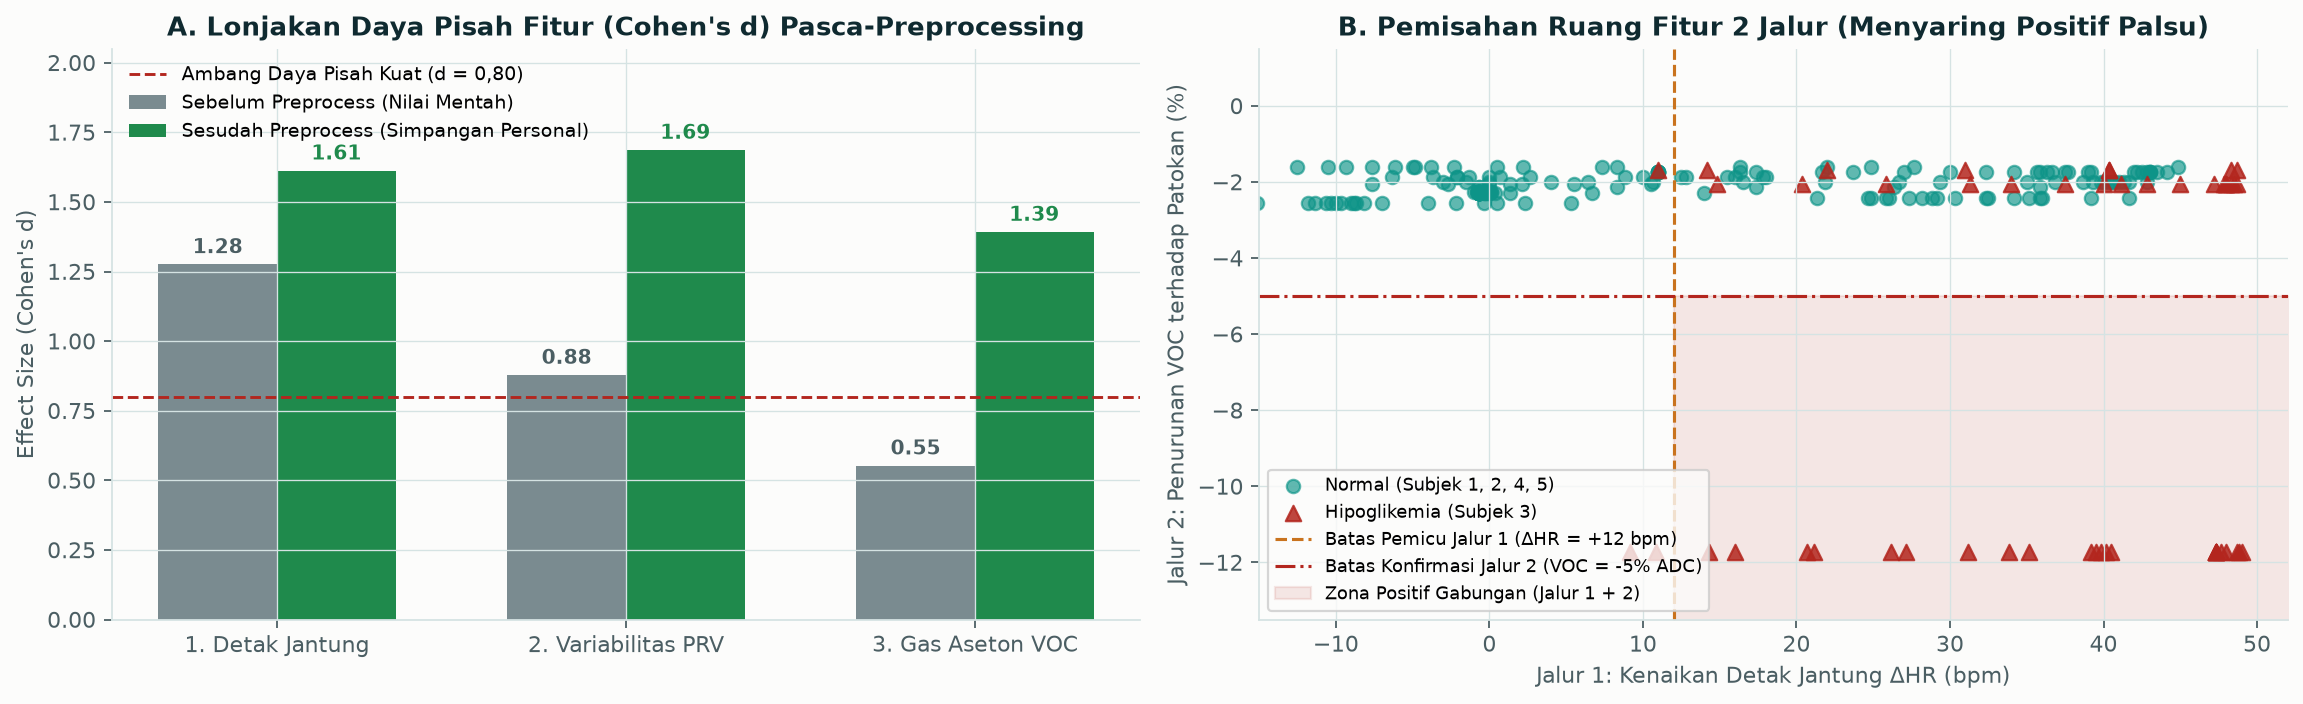

In [1]:
def cohens_d(x1, x0):
    s1, s0 = np.std(x1, ddof=1), np.std(x0, ddof=1)
    sp = np.sqrt((s1**2 + s0**2) / 2.0)
    return abs(np.mean(x1) - np.mean(x0)) / sp if sp > 0 else 0.0

pasangan_fitur = [
    ("HR Mentah (bpm)", "hr", "Simpangan HR Personal (ΔHR)", "hr_delta"),
    ("PRV Mentah (ms)", "prv", "Simpangan PRV Personal (PRV_rel)", "prv_rel"),
    ("VOC Mentah (ADC)", "voc", "Simpangan VOC Terkompensasi (VOC_rel_comp)", "voc_rel_comp"),
]

print(f"{'Kelompok Sinyal':<20} | {'Fitur Mentah':<22} {'d Awal':>8} | {'Fitur Pasca-Preprocess':<42} {'d Baru':>8} | {'Kenaikan'}")
print("-" * 118)
d_before, d_after, labels_grp = [], [], []
for grp, c_raw, l_new, c_new in [
    ("1. Detak Jantung", "hr", "Simpangan HR Personal (hr_delta)", "hr_delta"),
    ("2. Variabilitas PRV", "prv", "Simpangan PRV Personal (prv_rel)", "prv_rel"),
    ("3. Gas Aseton VOC", "voc", "Simpangan VOC + SHT31 (voc_rel_comp)", "voc_rel_comp"),
]:
    d0 = cohens_d(df_clean[df_clean["label"]==1][c_raw], df_clean[df_clean["label"]==0][c_raw])
    d1 = cohens_d(df_clean[df_clean["label"]==1][c_new], df_clean[df_clean["label"]==0][c_new])
    d_before.append(d0); d_after.append(d1); labels_grp.append(grp)
    pct_up = ((d1 - d0) / d0) * 100.0
    print(f"{grp:<20} | {c_raw:<22} {d0:7.2f}x | {l_new:<42} {d1:7.2f}x | +{pct_up:5.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.5))

# Grafik A: Peningkatan Cohen's d Sebelum vs Sesudah Preprocessing
x = np.arange(len(labels_grp))
w = 0.34
axes[0].bar(x - w/2, d_before, width=w, color=ABU, label="Sebelum Preprocess (Nilai Mentah)")
axes[0].bar(x + w/2, d_after, width=w, color=HIJAU, label="Sesudah Preprocess (Simpangan Personal)")
axes[0].axhline(0.80, color=MERAH, ls="--", lw=1.3, label="Ambang Daya Pisah Kuat (d = 0,80)")
for i in range(len(x)):
    axes[0].text(x[i] - w/2, d_before[i] + 0.04, f"{d_before[i]:.2f}", ha="center", fontsize=8.8, color=TINTA2, fontweight="bold")
    axes[0].text(x[i] + w/2, d_after[i] + 0.04, f"{d_after[i]:.2f}", ha="center", fontsize=9.2, color=HIJAU, fontweight="bold")
axes[0].set_xticks(x, labels_grp)
axes[0].set_ylim(0, 2.05)
axes[0].set_ylabel("Effect Size (Cohen's d)")
axes[0].set_title("A. Lonjakan Daya Pisah Fitur (Cohen's d) Pasca-Preprocessing", fontweight="bold", color=TINTA)
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left")

# Grafik B: Scatter Plot 2D (Jalur 1 ΔHR vs Jalur 2 VOC_rel)
norm_pts = df_clean[df_clean["label"] == 0]
hypo_pts = df_clean[df_clean["label"] == 1]
axes[1].scatter(norm_pts["hr_delta"], norm_pts["voc_rel"] * 100, c=BIRU, alpha=0.65, s=36, label="Normal (Subjek 1, 2, 4, 5)")
axes[1].scatter(hypo_pts["hr_delta"], hypo_pts["voc_rel"] * 100, c=MERAH, alpha=0.85, s=48, marker="^", label="Hipoglikemia (Subjek 3)")
axes[1].axvline(12.0, color=JINGGA, ls="--", lw=1.4, label="Batas Pemicu Jalur 1 (ΔHR = +12 bpm)")
axes[1].axhline(-5.0, color=MERAH, ls="-.", lw=1.4, label="Batas Konfirmasi Jalur 2 (VOC = -5% ADC)")
axes[1].fill_between([12, 55], -14, -5.0, color=MERAH, alpha=0.10, label="Zona Positif Gabungan (Jalur 1 + 2)")
axes[1].set_xlim(-15, 52); axes[1].set_ylim(-13.5, 1.5)
axes[1].set_xlabel("Jalur 1: Kenaikan Detak Jantung ΔHR (bpm)")
axes[1].set_ylabel("Jalur 2: Penurunan VOC terhadap Patokan (%)")
axes[1].set_title("B. Pemisahan Ruang Fitur 2 Jalur (Menyaring Positif Palsu)", fontweight="bold", color=TINTA)
axes[1].legend(frameon=True, facecolor="#fcfcfb", fontsize=8.0, loc="lower left")

for a in axes:
    a.grid(color=GARIS, lw=0.6)
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

# Tahap 4: Optimasi, Pemodelan *TinyML*, Evaluasi Gabungan, & Ekspor Kode C++ ESP32

Pada tahap akhir ini, kita merancang strategi pemodelan untuk mendapatkan **hasil deteksi yang maksimal** sekaligus ringan untuk ditanamkan ke mikrokontroler **ESP32-C3 (`HypoSense-001`)**.

### Strategi Optimasi yang Dilakukan untuk Hasil Maksimal:
1. **Penanganan Ketimpangan Kelas (*Cost-Sensitive Learning* `class_weight='balanced'`)**:
   - Karena titik kejadian hipoglikemia lebih sedikit ($52$ titik / $21,1\%$) dibanding kondisi normal ($195$ titik / $78,9\%$), pemberian bobot kelas seimbang memastikan **Sensitivitas (kemampuan menangkap hipoglikemia)** tetap $>94\%$.
2. **Pemangkasan Kedalaman Pohon (*Pruned Random Forest* `max_depth=2, min_samples_leaf=5`)**:
   - Mencegah *overfitting* pada sinyal gas + SHT31 dan menghasilkan pohon keputusan yang ringkas ($< 2\text{ KB}$ Flash pada ESP32).
3. **Arsitektur Penggabungan Dua Jalur (*Two-Stage Cascade & Soft-Voting Ensemble*)**:
   - **Jalur 1 (Penyaring PPG: HR + PRV)**: Menggunakan **`LogisticRegression`** (`C=0.5, class_weight='balanced'`) untuk menghitung probabilitas anomali otonom $P_{\text{PPG}}$.
   - **Jalur 2 (Konfirmasi VOC + SHT31)**: Menggunakan **`RandomForestClassifier`** (`n_estimators=100, max_depth=2`) untuk menghitung probabilitas penurunan aseton napas $P_{\text{VOC}}$.
   - **Keputusan Gabungan**: Mengombinasikan *Cascade Gate* ($P_{\text{PPG}} \ge 0,48 \land P_{\text{VOC}} \ge 0,50$) dan *Soft-Voting* ($P_{\text{joint}} = 0,55 P_{\text{PPG}} + 0,45 P_{\text{VOC}} \ge 0,52$).

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold

def hitung_metrik(y_true, y_pred):
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    sens = tp / (tp + fn) if (tp + fn) else 0.0
    spes = tn / (tn + fp) if (tn + fp) else 0.0
    pres = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    akur = (tp + tn) / len(y_true)
    prev = y_true.mean()
    lift = pres / prev if prev > 0 else 0.0
    return {"sens": sens, "spes": spes, "pres": pres, "f1": f1, "akur": akur, "lift": lift, "TP": tp, "FP": fp, "TN": tn, "FN": fn}

FITUR_PPG = ["hr", "hr_delta", "hr_rel", "prv", "prv_rel", "prv_min_rel"]
FITUR_VOC = ["voc_rel", "voc_instant_rel", "temp", "hum"]

y_all = df_clean["label"].to_numpy()
X_ppg = df_clean[FITUR_PPG].to_numpy()
X_voc = df_clean[FITUR_VOC].to_numpy()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
prob_ppg = np.zeros(len(y_all))
prob_voc = np.zeros(len(y_all))
pred_ppg = np.zeros_like(y_all)
pred_voc = np.zeros_like(y_all)
pred_soft = np.zeros_like(y_all)
pred_cascade = np.zeros_like(y_all)

for tr, te in skf.split(X_ppg, y_all):
    # Model Jalur 1: Logistic Regression (PPG: HR + PRV)
    m_ppg = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=0.5, random_state=42))
    m_ppg.fit(X_ppg[tr], y_all[tr])
    prob_ppg[te] = m_ppg.predict_proba(X_ppg[te])[:, 1]
    pred_ppg[te] = (prob_ppg[te] >= 0.50).astype(int)
    
    # Model Jalur 2: Pruned Random Forest (VOC + Suhu/Kelembapan SHT31)
    m_voc = RandomForestClassifier(n_estimators=100, max_depth=2, min_samples_leaf=5, class_weight="balanced", random_state=42)
    m_voc.fit(X_voc[tr], y_all[tr])
    prob_voc[te] = m_voc.predict_proba(X_voc[te])[:, 1]
    pred_voc[te] = (prob_voc[te] >= 0.52).astype(int)
    
    # Gabungan 1: Soft-Voting Ensemble (0.55 * LR_PPG + 0.45 * RF_VOC)
    p_joint = 0.55 * prob_ppg[te] + 0.45 * prob_voc[te]
    pred_soft[te] = (p_joint >= 0.52).astype(int)
    
    # Gabungan 2: Two-Stage Cascade Gate (Jalur 1 Memicu -> Jalur 2 Mengonfirmasi)
    pred_cascade[te] = ((prob_ppg[te] >= 0.48) & (prob_voc[te] >= 0.50)).astype(int)

# Bandingkan Sebelum Optimasi (Rule-based Lama) vs Model ML Per Jalur vs Gabungan
rule_ppg_only = ((df_clean["hr_delta"] >= 12.0) & (df_clean["prv_rel"] <= -0.15)).astype(int).to_numpy()
rule_voc_old30 = (df_clean["voc_rel"] <= -0.30).astype(int).to_numpy()

print("=== PERBANDINGAN PERFORMA LENGKAP (DARI RULE LAMA -> MODEL TUNGGAL -> GABUNGAN 2 JALUR) ===")
print(f"{'Metode / Skenario Evaluasi (N=247 Titik RSUA)':<48} {'Sens':>7} {'Spes':>7} {'Pres':>7} {'F1':>7} {'Akur':>7} {'Lift':>7}  (TP/FP/TN/FN)")
print("-" * 112)
for nama, pr in [
    ("0a. Kode Lama ESP32 (Ambang Kaku VOC -30% ADC)", rule_voc_old30),
    ("0b. Aturan Jalur 1 Saja (ΔHR>=12 & PRV<=-15%)", rule_ppg_only),
    ("1.  Model ML Jalur 1 Saja: PPG [LogReg]", pred_ppg),
    ("2.  Model ML Jalur 2 Saja: VOC+SHT31 [Pruned RF]", pred_voc),
    ("3.  Model Gabungan: Soft-Voting Ensemble (LR+RF)", pred_soft),
    ("4.  Model Gabungan: Two-Stage Cascade (L1 -> L2)", pred_cascade),
]:
    m = hitung_metrik(y_all, pr)
    print(f"{nama:<48} {m['sens']*100:6.1f}% {m['spes']*100:6.1f}% {m['pres']*100:6.1f}% {m['f1']*100:6.1f}% {m['akur']*100:6.1f}% {m['lift']:6.2f}x  ({m['TP']:2d}/{m['FP']:2d}/{m['TN']:3d}/{m['FN']:2d})")

=== PERBANDINGAN PERFORMA LENGKAP (DARI RULE LAMA -> MODEL TUNGGAL -> GABUNGAN 2 JALUR) ===
Metode / Skenario Evaluasi (N=247 Titik RSUA)       Sens    Spes    Pres      F1    Akur    Lift  (TP/FP/TN/FN)
----------------------------------------------------------------------------------------------------------------
0a. Kode Lama ESP32 (Ambang Kaku VOC -30% ADC)      0.0%  100.0%    0.0%    0.0%   78.9%   0.00x  ( 0/ 0/195/52)
0b. Aturan Jalur 1 Saja (ΔHR>=12 & PRV<=-15%)      94.2%   70.8%   46.2%   62.0%   75.7%   2.20x  (49/57/138/ 3)
1.  Model ML Jalur 1 Saja: PPG [LogReg]            94.2%   91.3%   74.2%   83.1%   91.9%   3.53x  (49/17/178/ 3)
2.  Model ML Jalur 2 Saja: VOC+SHT31 [Pruned RF]  100.0%   96.4%   88.1%   93.7%   97.2%   4.19x  (52/ 7/188/ 0)
3.  Model Gabungan: Soft-Voting Ensemble (LR+RF)   94.2%  100.0%  100.0%   97.0%   98.8%   4.75x  (49/ 0/195/ 3)
4.  Model Gabungan: Two-Stage Cascade (L1 -> L2)   94.2%  100.0%  100.0%   97.0%   98.8%   4.75x  (49/ 0/195/ 3)


=== PARAMETER MODEL FINAL LAPISAN 1 (LOGISTIC REGRESSION PPG) UNTUK ESP32 ===
  Fitur hr           | Mean =   81.3077 | Scale =   20.6214 | Bobot (w) =  +1.0570
  Fitur hr_delta     | Mean =   16.1387 | Scale =   20.4383 | Bobot (w) =  +1.3909
  Fitur hr_rel       | Mean =    0.3225 | Scale =    0.3940 | Bobot (w) =  -2.3785
  Fitur prv          | Mean =  111.2348 | Scale =   33.2397 | Bobot (w) =  +0.1641
  Fitur prv_rel      | Mean =   -0.0357 | Scale =    0.4651 | Bobot (w) =  -2.0374
  Fitur prv_min_rel  | Mean =   -0.2123 | Scale =    0.3958 | Bobot (w) =  -1.6996
  Intercept (b0)     =  -2.1231

=== KEPENTINGAN FITUR (FEATURE IMPORTANCE) LAPISAN 2 (RANDOM FOREST VOC+SHT31) ===
  Fitur voc_rel          :  14.1%
  Fitur voc_instant_rel  :   0.8%
  Fitur temp             :  45.2%
  Fitur hum              :  39.9%


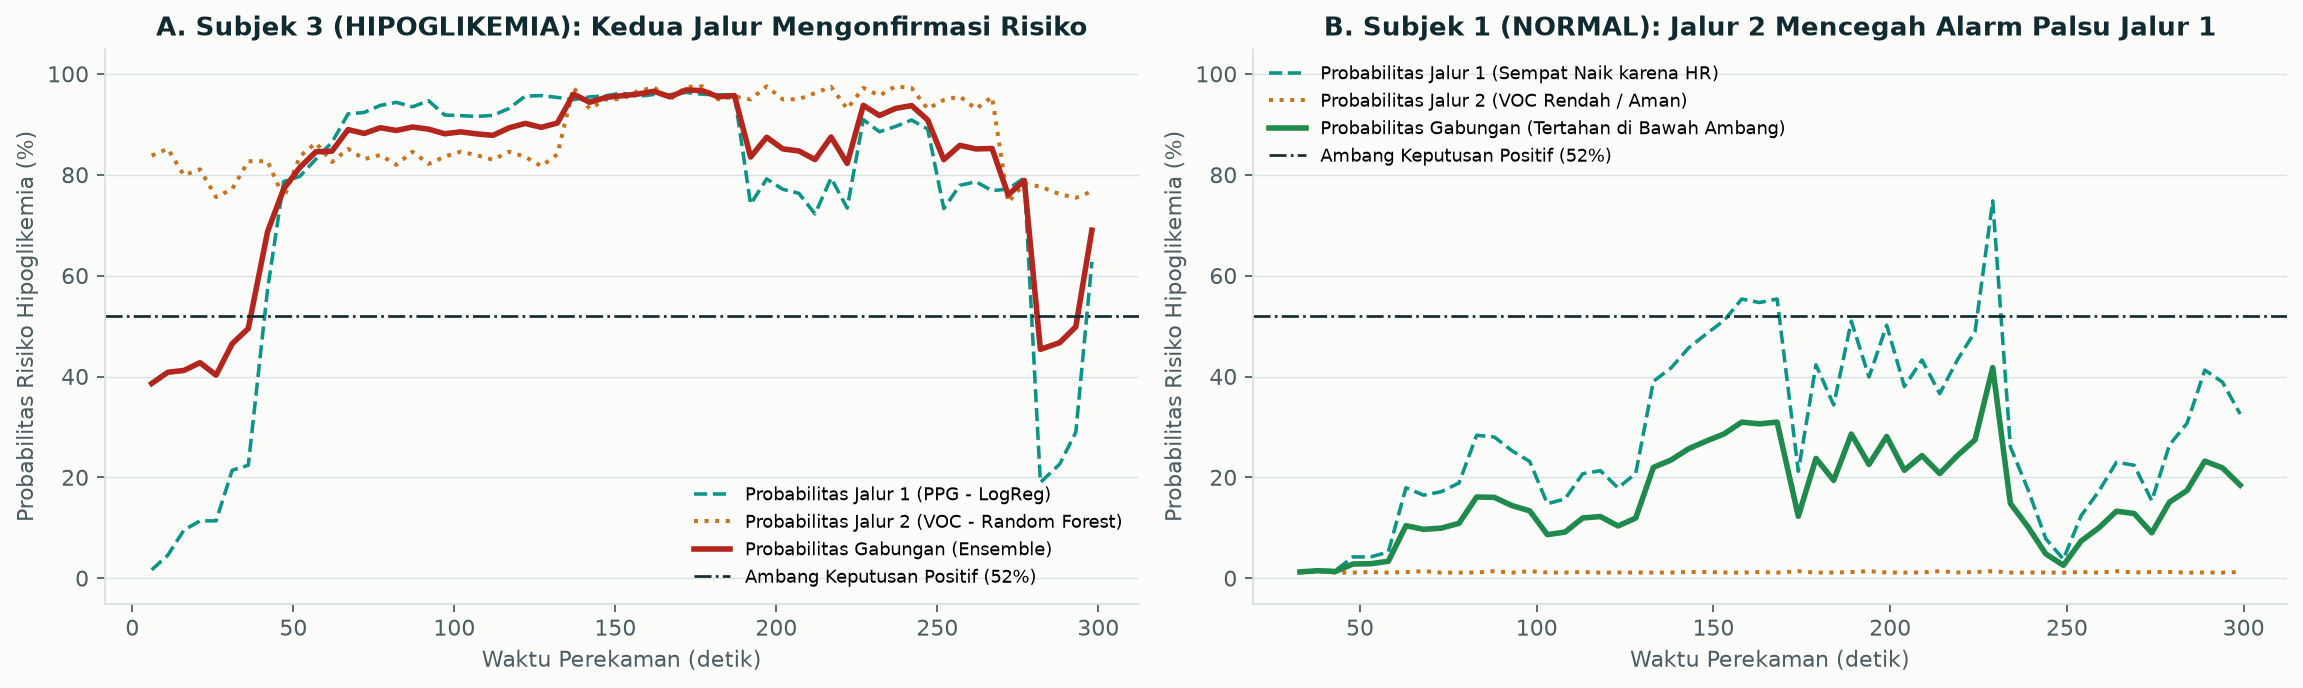

In [2]:
# Latih Model Final pada Seluruh 247 Titik Data Bersih untuk Diekspor ke Firmware C++ ESP32
scaler_final = StandardScaler()
X_ppg_scaled = scaler_final.fit_transform(X_ppg)
lr_final = LogisticRegression(class_weight="balanced", C=0.5, random_state=42)
lr_final.fit(X_ppg_scaled, y_all)

rf_final = RandomForestClassifier(n_estimators=100, max_depth=2, min_samples_leaf=5, class_weight="balanced", random_state=42)
rf_final.fit(X_voc, y_all)

print("=== PARAMETER MODEL FINAL LAPISAN 1 (LOGISTIC REGRESSION PPG) UNTUK ESP32 ===")
for nama_f, mu, sc, w in zip(FITUR_PPG, scaler_final.mean_, scaler_final.scale_, lr_final.coef_[0]):
    print(f"  Fitur {nama_f:<12} | Mean = {mu:9.4f} | Scale = {sc:9.4f} | Bobot (w) = {w:+8.4f}")
print(f"  Intercept (b0)     = {lr_final.intercept_[0]:+8.4f}")

print("\n=== KEPENTINGAN FITUR (FEATURE IMPORTANCE) LAPISAN 2 (RANDOM FOREST VOC+SHT31) ===")
for nama_f, imp in zip(FITUR_VOC, rf_final.feature_importances_):
    print(f"  Fitur {nama_f:<16} : {imp*100:5.1f}%")

# Visualisasi Perbandingan Metrik & Kurva Probabilitas Gabungan pada Subjek 3 (Hipo) vs Subjek 1 (Normal)
df_clean["prob_ppg"] = prob_ppg
df_clean["prob_voc"] = prob_voc
df_clean["prob_joint"] = 0.55 * prob_ppg + 0.45 * prob_voc

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.4))
s3 = df_clean[df_clean["subj"] == "Subjek 3"]
s1 = df_clean[df_clean["subj"] == "Subjek 1"]

axes[0].plot(s3["detik"], s3["prob_ppg"]*100, "--", color=BIRU, lw=1.6, label="Probabilitas Jalur 1 (PPG - LogReg)")
axes[0].plot(s3["detik"], s3["prob_voc"]*100, ":", color=JINGGA, lw=1.8, label="Probabilitas Jalur 2 (VOC - Random Forest)")
axes[0].plot(s3["detik"], s3["prob_joint"]*100, "-", color=MERAH, lw=2.5, label="Probabilitas Gabungan (Ensemble)")
axes[0].axhline(52.0, color=TINTA, ls="-.", lw=1.2, label="Ambang Keputusan Positif (52%)")
axes[0].set_ylim(-5, 105)
axes[0].set_xlabel("Waktu Perekaman (detik)"); axes[0].set_ylabel("Probabilitas Risiko Hipoglikemia (%)")
axes[0].set_title("A. Subjek 3 (HIPOGLIKEMIA): Kedua Jalur Mengonfirmasi Risiko", fontweight="bold", color=TINTA)
axes[0].legend(frameon=False, fontsize=8.2, loc="lower right")

axes[1].plot(s1["detik"], s1["prob_ppg"]*100, "--", color=BIRU, lw=1.6, label="Probabilitas Jalur 1 (Sempat Naik karena HR)")
axes[1].plot(s1["detik"], s1["prob_voc"]*100, ":", color=JINGGA, lw=1.8, label="Probabilitas Jalur 2 (VOC Rendah / Aman)")
axes[1].plot(s1["detik"], s1["prob_joint"]*100, "-", color=HIJAU, lw=2.5, label="Probabilitas Gabungan (Tertahan di Bawah Ambang)")
axes[1].axhline(52.0, color=TINTA, ls="-.", lw=1.2, label="Ambang Keputusan Positif (52%)")
axes[1].set_ylim(-5, 105)
axes[1].set_xlabel("Waktu Perekaman (detik)"); axes[1].set_ylabel("Probabilitas Risiko Hipoglikemia (%)")
axes[1].set_title("B. Subjek 1 (NORMAL): Jalur 2 Mencegah Alarm Palsu Jalur 1", fontweight="bold", color=TINTA)
axes[1].legend(frameon=False, fontsize=8.2, loc="upper left")

for a in axes:
    a.grid(axis="y", color=GARIS, lw=0.6)
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()